Week 2 notebook, linear regression with lasso, ridge, and elastic net, Mike Hembree

Quick background for whoever is reviewing this from another project. My actual capstone is an early warning model for ICU delirium built on MIMIC-IV, a de-identified electronic health record database from Beth Israel Deaconess Medical Center. The real pipeline uses the full credentialed MIMIC-IV database, around 16,800 ICU stays, and predicts whether a patient will screen positive for delirium on the CAM-ICU assessment. Getting the full database requires PhysioNet credentialing though, so for this week's regression exercise I pulled the MIMIC-IV Clinical Database Demo instead, which is the same schema and the same tables but an openly available 100 patient, 140 ICU stay subset. The numbers in this notebook come from that demo subset, not the full cohort, so they're a lot noisier than what I'd expect at full scale, but the pipeline logic is the same.

For this week the assignment wants linear regression plus lasso, ridge, and elastic net, which all want a continuous target, so instead of predicting delirium status directly I'm predicting ICU length of stay in days. Delirium is one of the strongest known drivers of longer ICU stays, so this is still very much in the spirit of the capstone question, just phrased as a regression problem instead of a classification one.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

The demo comes as a folder of raw MIMIC-IV tables (icustays, patients, chartevents, and so on), not a ready made feature table, so the first chunk of work is basically a scaled down version of the feature engineering I did for Milestone 3. I pulled icustays for the length of stay and care unit, patients for age and gender, and then averaged a handful of vitals out of chartevents for each stay using the standard MIMIC item ids for heart rate, blood pressure, respiratory rate, temperature, and oxygen saturation. I also pulled the three GCS component items and added them into a total GCS score, and pulled the CAM-ICU style delirium assessment item to build a flag for whether a stay ever had a positive delirium screen.

In [2]:
# load the raw tables
icu = pd.read_csv('mimic-iv-clinical-database-demo-2.2/icu/icustays.csv')
pts = pd.read_csv('mimic-iv-clinical-database-demo-2.2/hosp/patients.csv')
ce = pd.read_csv('mimic-iv-clinical-database-demo-2.2/icu/chartevents.csv', low_memory = False)

icu.shape, pts.shape, ce.shape

((140, 8), (100, 6), (668862, 11))

In [3]:
# item ids for vitals, GCS components, and the delirium assessment, pulled from d_items
vitals = {220045: 'heart_rate', 220179: 'sbp', 220180: 'dbp', 220210: 'resp_rate', 223761: 'temp_f', 220277: 'spo2'}
gcs_items = {223900: 'gcs_verbal', 223901: 'gcs_motor', 220739: 'gcs_eye'}
delirium_item = 228332

feat = icu[['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'los']].copy()
feat = feat.merge(pts[['subject_id', 'gender', 'anchor_age']], on = 'subject_id', how = 'left')

for iid, name in vitals.items():
    stay_avg = ce[ce.itemid == iid].groupby('stay_id')['valuenum'].mean().rename(name)
    feat = feat.merge(stay_avg, on = 'stay_id', how = 'left')

for iid, name in gcs_items.items():
    stay_min = ce[ce.itemid == iid].groupby('stay_id')['valuenum'].min().rename(name)
    feat = feat.merge(stay_min, on = 'stay_id', how = 'left')

feat['gcs_total_min'] = feat['gcs_verbal'] + feat['gcs_motor'] + feat['gcs_eye']

delir = ce[ce.itemid == delirium_item]
delir_flag = delir.groupby('stay_id')['value'].apply(lambda v: int((v == 'Positive').any())).rename('delirium_positive')
feat = feat.merge(delir_flag, on = 'stay_id', how = 'left')
feat['delirium_positive'] = feat['delirium_positive'].fillna(0)
feat['gender'] = (feat['gender'] == 'M').astype(int)

feat.shape

(140, 18)

In [4]:
feat.isna().sum()

subject_id           0
hadm_id              0
stay_id              0
first_careunit       0
los                  0
gender               0
anchor_age           0
heart_rate           0
sbp                  1
dbp                  1
resp_rate            0
temp_f               2
spo2                 0
gcs_verbal           0
gcs_motor            0
gcs_eye              0
gcs_total_min        0
delirium_positive    0
dtype: int64

140 ICU stays and only a couple of missing values here and there, mostly one or two stays that never got a blood pressure or temperature reading logged. I'm just filling those with the column median rather than dropping the rows, since losing rows out of a dataset this small would hurt a lot more than the small amount of imputation error. Worth noting that 32 percent of stays in this subset had at least one positive delirium screen, which lines up reasonably well with the 26.3 percent rate I found across the full cohort in Milestone 3.

In [5]:
# pick predictors and target, fill the small amount of missingness with the median
cols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min', 'delirium_positive']
target = 'los'

data = feat[cols + [target]].copy()
for c in cols:
    data[c] = data[c].fillna(data[c].median())

data.describe()

,anchor_age,gender,heart_rate,sbp,dbp,resp_rate,temp_f,spo2,gcs_total_min,delirium_positive,los
count,140.000000,140.00000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000
mean,62.014286,0.55000,88.662321,117.726890,64.145347,19.584751,98.420981,96.666239,9.585714,0.321429,3.679379
std,15.424444,0.49928,13.242733,15.796462,9.928260,3.809978,0.665036,1.934861,5.157917,0.468702,3.896354
min,21.000000,0.00000,54.909091,62.000000,31.000000,10.333333,94.600000,83.500000,3.000000,0.000000,0.023727
25%,52.000000,0.00000,79.396205,108.154837,59.261858,16.946154,98.112277,95.769378,3.000000,0.000000,1.170663
50%,63.000000,1.00000,87.894792,116.259259,63.428571,19.320820,98.400000,96.844571,11.000000,0.000000,2.155093
75%,72.000000,1.00000,97.885451,127.469156,69.258908,21.723752,98.755833,97.769397,15.000000,1.000000,4.907749
max,91.000000,1.00000,117.690852,158.000000,88.691450,33.500000,100.373125,100.000000,15.000000,1.000000,20.528681


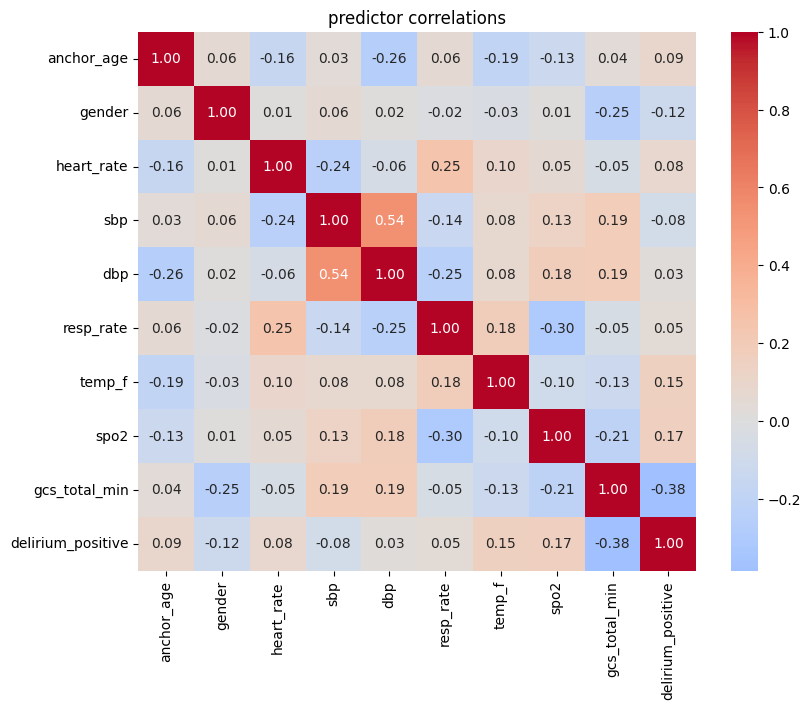

In [6]:
# correlation check on the predictors
plt.figure(figsize = (9, 7))
sns.heatmap(data[cols].corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0)
plt.title('predictor correlations')
plt.show()

Sbp and dbp are correlated like you'd expect two blood pressure readings to be, and gcs_total_min and delirium_positive have a decent negative correlation too, which makes clinical sense since a lower GCS (worse neuro status) tends to go along with a positive delirium screen. Nothing here is extreme enough to be a real problem, but again this is exactly the kind of setup where ridge and lasso can behave differently from plain linear regression.

In [7]:
# train test split, then scale
X = data[cols]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [8]:
# plain linear regression baseline
lr = LinearRegression()
lr.fit(X_train_s, y_train)
lr_pred = lr.predict(X_test_s)

lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = mean_squared_error(y_test, lr_pred) ** 0.5
print('linear r2:', lr_r2)
print('linear rmse:', lr_rmse)
pd.Series(lr.coef_, index = cols).sort_values()

linear r2: 0.33808019408337464
linear rmse: 3.1314828257057123


gcs_total_min       -1.190864
sbp                 -0.232786
gender              -0.156863
spo2                -0.124206
dbp                 -0.102435
resp_rate            0.060423
anchor_age           0.140662
temp_f               0.348067
heart_rate           0.421437
delirium_positive    1.413917
dtype: float64

R squared around 0.34 out of the gate, which is honestly better than I expected out of a 140 row demo subset. Gcs_total_min and delirium_positive have by far the largest coefficients, both in the direction you'd clinically expect, worse GCS and a positive delirium screen both push length of stay up. Heart rate and temperature also came in with a fair amount of weight, which could be picking up on general acute illness severity. Let's see what the regularized versions do.

In [9]:
# ridge with cross validated alpha
ridge = RidgeCV(alphas = np.logspace(-3, 3, 50))
ridge.fit(X_train_s, y_train)
ridge_pred = ridge.predict(X_test_s)

ridge_r2 = r2_score(y_test, ridge_pred)
ridge_rmse = mean_squared_error(y_test, ridge_pred) ** 0.5
print('best alpha:', ridge.alpha_)
print('ridge r2:', ridge_r2)
print('ridge rmse:', ridge_rmse)
pd.Series(ridge.coef_, index = cols).sort_values()

best alpha: 59.636233165946365
ridge r2: 0.31162790818526076
ridge rmse: 3.1934415635193947


gcs_total_min       -0.862166
sbp                 -0.239562
dbp                 -0.119446
gender              -0.086227
spo2                 0.011256
resp_rate            0.102253
anchor_age           0.110450
heart_rate           0.287439
temp_f               0.296360
delirium_positive    1.016652
dtype: float64

In [10]:
# lasso with cross validated alpha
lasso = LassoCV(alphas = np.logspace(-3, 1, 50), max_iter = 10000, random_state = 42)
lasso.fit(X_train_s, y_train)
lasso_pred = lasso.predict(X_test_s)

lasso_r2 = r2_score(y_test, lasso_pred)
lasso_rmse = mean_squared_error(y_test, lasso_pred) ** 0.5
print('best alpha:', lasso.alpha_)
print('lasso r2:', lasso_r2)
print('lasso rmse:', lasso_rmse)
pd.Series(lasso.coef_, index = cols).sort_values()

best alpha: 0.4941713361323833
lasso r2: 0.29594969747046385
lasso rmse: 3.2296033792159897


gcs_total_min       -0.869996
anchor_age           0.000000
sbp                 -0.000000
gender              -0.000000
temp_f               0.000000
resp_rate            0.000000
spo2                -0.000000
dbp                 -0.000000
heart_rate           0.025801
delirium_positive    1.160502
dtype: float64

This time lasso actually did real feature selection instead of just shrinking everything a little. It zeroed out age, gender, both blood pressure readings, respiratory rate, temperature, and spo2 completely, and kept only heart rate, gcs_total_min, and delirium_positive. That's a pretty clean result, it's basically saying that once you know a patient's GCS and delirium status, the vitals and demographics in this feature set aren't adding much on top for predicting length of stay, at least not in a subset this small.

In [11]:
# elastic net, searching over alpha and the l1 ratio together
enet = ElasticNetCV(alphas = np.logspace(-3, 1, 50), l1_ratio = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1], max_iter = 10000, random_state = 42)
enet.fit(X_train_s, y_train)
enet_pred = enet.predict(X_test_s)

enet_r2 = r2_score(y_test, enet_pred)
enet_rmse = mean_squared_error(y_test, enet_pred) ** 0.5
print('best alpha:', enet.alpha_)
print('best l1 ratio:', enet.l1_ratio_)
print('elastic net r2:', enet_r2)
print('elastic net rmse:', enet_rmse)
pd.Series(enet.coef_, index = cols).sort_values()

best alpha: 0.4941713361323833
best l1 ratio: 1.0
elastic net r2: 0.29594969747046385
elastic net rmse: 3.2296033792159897


gcs_total_min       -0.869996
anchor_age           0.000000
sbp                 -0.000000
gender              -0.000000
temp_f               0.000000
resp_rate            0.000000
spo2                -0.000000
dbp                 -0.000000
heart_rate           0.025801
delirium_positive    1.160502
dtype: float64

In [12]:
# side by side comparison
results = pd.DataFrame({
    'model': ['linear', 'ridge', 'lasso', 'elastic net'],
    'r2': [lr_r2, ridge_r2, lasso_r2, enet_r2],
    'rmse': [lr_rmse, ridge_rmse, lasso_rmse, enet_rmse]
})
results

,model,r2,rmse
0,linear,0.338080,3.131483
1,ridge,0.311628,3.193442
2,lasso,0.295950,3.229603
3,elastic net,0.295950,3.229603


Cross validation picked an l1 ratio of 1.0 for elastic net, meaning it landed on the exact same solution as lasso, it didn't find any benefit to blending in the ridge penalty for this dataset. Plain linear regression actually edged out all three regularized versions on this particular test split, r squared around 0.34 versus 0.30 to 0.31 for the others, though with only 28 stays in the test set that gap is well within the range I'd expect from noise alone rather than a real difference in model quality.

The bigger takeaway for the capstone is which variables kept showing up as important across every version of the model, gcs_total_min and delirium_positive. Both are consistent with what the clinical literature already says about delirium extending ICU stays, and it's reassuring to see that story show up even in a rough 140 stay demo subset. Once I have full PhysioNet credentialed access to the complete cohort, I'd want to rerun this same pipeline at scale, since the regularized models should behave a lot more meaningfully once there's enough data for them to actually trade off bias and variance instead of just reacting to a tiny test set. I'd also want to bring in more of the extended labs and trajectory features from the Milestone 3 pipeline, since this demo notebook only used a handful of basic vitals and GCS, not the full 187 feature set.